# 02 - Can a model label AI incidents by itself?

Only 34% of 2026 incidents have a risk type yet, so recent trends can't be trusted. Here I train a model
that reads an incident's description and predicts its risk type (the 7 MIT risk domains).

## 1. Prepare the data

- Load incidents and the MIT risk types, and join them on the incident ID (same as notebook 01).
- Input for the model: `description` (the text).
- Output: `Risk Domain` (one of 7 types).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

incidents = pd.read_csv("data/mongodump_full_snapshot/incidents.csv")
mit = pd.read_csv("data/mongodump_full_snapshot/classifications_MIT.csv")

data = incidents.merge(mit, left_on="incident_id", right_on="Incident ID", how="inner")
data["year"] = pd.to_datetime(data["date"]).dt.year
data = data[["incident_id", "year", "title", "description", "Risk Domain"]]

print("Labelled incidents:", len(data))
data.head()

Labelled incidents: 1498


,incident_id,year,title,description,Risk Domain
0,23,2017,Las Vegas Self-Driving Bus Involved in Accident,A self-driving public shuttle by Keolis North ...,"7. AI system safety, failures, and limitations"
1,4,2018,Uber AV Killed Pedestrian in Arizona,An Uber autonomous vehicle (AV) in autonomous ...,"7. AI system safety, failures, and limitations"
2,1,2015,Google’s YouTube Kids App Presents Inappropria...,YouTube’s content filtering and recommendation...,1. Discrimination and Toxicity
3,18,2015,Gender Biases of Google Image Search,Google Image returns results that under-repres...,1. Discrimination and Toxicity
4,12,2016,Common Biases of Vector Embeddings,Researchers from Boston University and Microso...,1. Discrimination and Toxicity


## 2. Split by year (not random)

Like in my TLB v2 project: if I split randomly, the model can see very similar incidents in train and
test (for example many deepfake scams from the same month), and the score looks better than it really is.
So I train on the past and test on the future, which is how the model would really be used.

- train: up to 2023
- validation: 2024 (for choosing settings)
- test: 2025 and 2026 (only used at the end)

In [2]:
train = data[data["year"] <= 2023]
val = data[data["year"] == 2024]
test = data[data["year"] >= 2025]

print("Train:", len(train), " Val:", len(val), " Test:", len(test))

Train: 695  Val: 293  Test: 510


### How different are the years?

`normalize="columns"` turns counts into percentages of each column, so the three splits can be compared.

In [3]:
split_name = pd.cut(data["year"], [0, 2023, 2024, 2100], labels=["train (<=2023)", "val (2024)", "test (2025+)"])
mix = pd.crosstab(data["Risk Domain"], split_name, normalize="columns") * 100
mix.round(0)

year,train (<=2023),val (2024),test (2025+)
Risk Domain,,,
1. Discrimination and Toxicity,26.0,10.0,6.0
2. Privacy & Security,9.0,6.0,7.0
3. Misinformation,9.0,17.0,16.0
4. Malicious Actors & Misuse,18.0,53.0,56.0
5. Human-Computer Interaction,3.0,1.0,4.0
6. Socioeconomic & Environmental Harms,2.0,1.0,1.0
"7. AI system safety, failures, and limitations",33.0,11.0,10.0


## 3. Baseline: always guess the most common type

Before any ML, a very simple "model": always predict the type that is most common in the training data.
If my real model can't beat this, it's not useful.

- **Accuracy** = how many predictions are right.
- **Macro F1** = F1 for each of the 7 types, then the average. Small types count as much as big ones,
  so a model that ignores the small types gets a low macro F1 even if accuracy looks OK.

In [4]:
from sklearn.metrics import accuracy_score, f1_score

most_common = train["Risk Domain"].value_counts().idxmax()
print("Most common type in train:", most_common)

baseline_pred = [most_common] * len(test)

print("Baseline accuracy:", round(accuracy_score(test["Risk Domain"], baseline_pred), 3))
print("Baseline macro F1:", round(f1_score(test["Risk Domain"], baseline_pred, average="macro"), 3))

Most common type in train: 7. AI system safety, failures, and limitations
Baseline accuracy: 0.098
Baseline macro F1: 0.026


## 4. Model 1: TF-IDF + Logistic Regression

**TF-IDF** turns each description into numbers: one number per word, bigger when the word is common in
this description but rare in the others. So words like "the" get almost 0, and words like "deepfake"
or "chatbot" get high values.

- `ngram_range=(1, 2)`: use single words and pairs of words (for example "voice clone")
- `min_df=2`: ignore words that appear in only one description
- `stop_words="english"`: remove very common words like "the", "and"

**Logistic Regression** then learns which words point to which risk type.

- `class_weight="balanced"`: small types (like Socioeconomic, 15 in train) get more weight, so the model
  doesn't just ignore them

The `Pipeline` puts both steps together, so TF-IDF only learns its words from the training data
(no leakage from test).

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

model.fit(train["description"], train["Risk Domain"])

for name, part in [("Validation (2024)", val), ("Test (2025+)", test)]:
    pred = model.predict(part["description"])
    print(name)
    print("  accuracy:", round(accuracy_score(part["Risk Domain"], pred), 3))
    print("  macro F1:", round(f1_score(part["Risk Domain"], pred, average="macro"), 3))

Validation (2024)
  accuracy: 0.724
  macro F1: 0.51
Test (2025+)
  accuracy: 0.698
  macro F1: 0.445


### Results for each type (test set)

- **precision**: when the model says "type X", how often is it right?
- **recall**: of all real "type X" incidents, how many did the model find?
- **support**: how many test incidents have that type

In [6]:
from sklearn.metrics import classification_report

test_pred = model.predict(test["description"])
print(classification_report(test["Risk Domain"], test_pred, zero_division=0))

                                                precision    recall  f1-score   support

                1. Discrimination and Toxicity       0.23      0.17      0.19        30
                         2. Privacy & Security       0.62      0.69      0.65        35
                             3. Misinformation       0.48      0.55      0.51        84
                  4. Malicious Actors & Misuse       0.84      0.87      0.86       286
                 5. Human-Computer Interaction       0.62      0.26      0.37        19
        6. Socioeconomic & Environmental Harms       0.00      0.00      0.00         6
7. AI system safety, failures, and limitations       0.53      0.54      0.53        50

                                      accuracy                           0.70       510
                                     macro avg       0.48      0.44      0.45       510
                                  weighted avg       0.68      0.70      0.69       510



### Confusion matrix

Rows = the real type, columns = what the model predicted. The diagonal is correct. Everything else
shows which types the model mixes up.

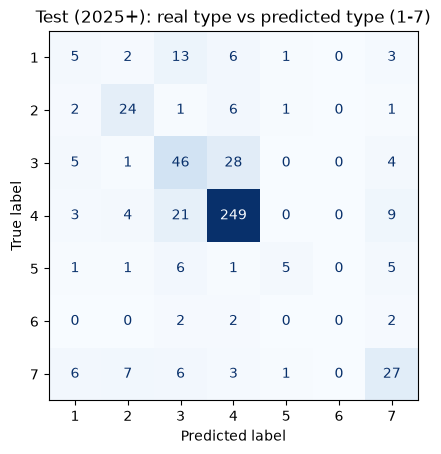

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

short_names = {name: name.split(".")[0] for name in data["Risk Domain"].unique()}
ConfusionMatrixDisplay.from_predictions(
    test["Risk Domain"].map(short_names), pd.Series(test_pred).map(short_names),
    labels=[str(i) for i in range(1, 8)], cmap="Blues", colorbar=False,
)
plt.title("Test (2025+): real type vs predicted type (1-7)")
plt.show()

### 4b. Does recent data help?

Train again on train + validation (up to 2024) and test on 2025+. 2024 is much closer to 2025 than the
old years, so if the score goes up a lot, it means the model needs recent examples to keep up.

In [8]:
train_val = pd.concat([train, val])
model.fit(train_val["description"], train_val["Risk Domain"])

pred = model.predict(test["description"])
print("Trained up to 2024, tested on 2025+")
print("  accuracy:", round(accuracy_score(test["Risk Domain"], pred), 3))
print("  macro F1:", round(f1_score(test["Risk Domain"], pred, average="macro"), 3))

Trained up to 2024, tested on 2025+
  accuracy: 0.741
  macro F1: 0.482


## 5. Model 2: sentence embeddings + Logistic Regression

TF-IDF only knows exact words. So "voice clone" and "fake audio" look completely different to it.

**Sentence embeddings** turn each description into a list of numbers that captures its *meaning*, so
descriptions about similar things end up close together, even with different words.

I use **model2vec** (`minishlab/potion-base-32M`), a small pre-trained embedding model. I can't use the
usual `sentence-transformers` library because PyTorch doesn't support my Intel Mac any more. model2vec
works without PyTorch. It is a bit less powerful, but much faster.

The model is downloaded once from Hugging Face (about 130 MB) the first time this runs.

In [9]:
from model2vec import StaticModel

embedder = StaticModel.from_pretrained("minishlab/potion-base-32M")

X_train = embedder.encode(train["description"].tolist())
X_val = embedder.encode(val["description"].tolist())
X_test = embedder.encode(test["description"].tolist())

print("Each description is now", X_train.shape[1], "numbers")

Each description is now 512 numbers


### Choose the setting on validation only

`C` controls how strongly the model fits the training data (small C = simpler model). I try a few values
and pick the best **on 2024 (validation)**. The test set is not used for choosing, same as in my TLB v2
project.

In [10]:
best_C, best_f1 = None, -1
for C in [0.1, 0.3, 1, 3, 10]:
    clf = LogisticRegression(max_iter=3000, class_weight="balanced", C=C)
    clf.fit(X_train, train["Risk Domain"])
    val_f1 = f1_score(val["Risk Domain"], clf.predict(X_val), average="macro")
    print("C =", C, " validation macro F1:", round(val_f1, 3))
    if val_f1 > best_f1:
        best_C, best_f1 = C, val_f1

print("Best C:", best_C)

C = 0.1  validation macro F1: 0.426
C = 0.3  validation macro F1: 0.46
C = 1  validation macro F1: 0.458
C = 3  validation macro F1: 0.458


C = 10  validation macro F1: 0.465
Best C: 10


In [11]:
emb_model = LogisticRegression(max_iter=3000, class_weight="balanced", C=best_C)
emb_model.fit(X_train, train["Risk Domain"])
emb_pred = emb_model.predict(X_test)

print("Test (2025+)")
print("  accuracy:", round(accuracy_score(test["Risk Domain"], emb_pred), 3))
print("  macro F1:", round(f1_score(test["Risk Domain"], emb_pred, average="macro"), 3))
print()
print(classification_report(test["Risk Domain"], emb_pred, zero_division=0))

Test (2025+)
  accuracy: 0.682
  macro F1: 0.492

                                                precision    recall  f1-score   support

                1. Discrimination and Toxicity       0.48      0.37      0.42        30
                         2. Privacy & Security       0.60      0.51      0.55        35
                             3. Misinformation       0.49      0.58      0.53        84
                  4. Malicious Actors & Misuse       0.83      0.79      0.81       286
                 5. Human-Computer Interaction       0.52      0.58      0.55        19
        6. Socioeconomic & Environmental Harms       0.00      0.00      0.00         6
7. AI system safety, failures, and limitations       0.53      0.64      0.58        50

                                      accuracy                           0.68       510
                                     macro avg       0.49      0.50      0.49       510
                                  weighted avg       0.69      0.68 

### 5b. With 2024 data added (same as 4b)

In [12]:
X_train_val = embedder.encode(pd.concat([train, val])["description"].tolist())
y_train_val = pd.concat([train, val])["Risk Domain"]

emb_model.fit(X_train_val, y_train_val)
pred = emb_model.predict(X_test)
print("Trained up to 2024, tested on 2025+")
print("  accuracy:", round(accuracy_score(test["Risk Domain"], pred), 3))
print("  macro F1:", round(f1_score(test["Risk Domain"], pred, average="macro"), 3))

Trained up to 2024, tested on 2025+
  accuracy: 0.745
  macro F1: 0.547


## Comparing everything (test 2025+)

In [13]:
tfidf_pred = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
]).fit(train["description"], train["Risk Domain"]).predict(test["description"])

emb_model.fit(X_train, train["Risk Domain"])

summary = pd.DataFrame({
    "Model (trained up to 2023)": ["Baseline (always most common)", "TF-IDF + LogReg", "Embeddings + LogReg"],
    "Accuracy": [accuracy_score(test["Risk Domain"], baseline_pred),
                 accuracy_score(test["Risk Domain"], tfidf_pred),
                 accuracy_score(test["Risk Domain"], emb_model.predict(X_test))],
    "Macro F1": [f1_score(test["Risk Domain"], baseline_pred, average="macro"),
                 f1_score(test["Risk Domain"], tfidf_pred, average="macro"),
                 f1_score(test["Risk Domain"], emb_model.predict(X_test), average="macro")],
}).round(3)
summary

,Model (trained up to 2023),Accuracy,Macro F1
0,Baseline (always most common),0.098,0.026
1,TF-IDF + LogReg,0.698,0.445
2,Embeddings + LogReg,0.682,0.492


## 6. Is the model using shortcuts?

In my maize project, the model looked at the table behind the leaf instead of the disease. Here I check
the same thing for text: is the model using words that really describe the harm, or shortcuts like
company names?

I use the TF-IDF model (trained up to 2023) because with TF-IDF I can see exactly which words it uses.

### 6a. Top 10 words for each type

Logistic Regression gives each word a weight for each type. A big positive weight means "this word
pushes the prediction towards this type".

In [14]:
import numpy as np

tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
]).fit(train["description"], train["Risk Domain"])

words = tfidf_model.named_steps["tfidf"].get_feature_names_out()
weights = tfidf_model.named_steps["clf"].coef_

for risk_type, w in zip(tfidf_model.classes_, weights):
    top10 = words[np.argsort(w)[-10:][::-1]]
    print(risk_type)
    print("   ", ", ".join(top10))

1. Discrimination and Toxicity
    black, bias, gender, racial, women, racist, disproportionately, tool, content, white
2. Privacy & Security
    data, consent, privacy, facial, recognition, users, private, facial recognition, scraped, training
3. Misinformation
    misinformation, ai generated, chatgpt, generated, ai, political, content, false, legal, quality
4. Malicious Actors & Misuse
    deepfake, voice, videos, video, fake, social media, media, generated, social, pornographic
5. Human-Computer Interaction
    driver, suicide, vehicle, mental, speed, police, dog, tesla, delivery, health
6. Socioeconomic & Environmental Harms
    competition, algorithm, scheduling, ranking, search, shopping, fair, workers, impacted, boost
7. AI system safety, failures, and limitations
    autonomous, robot, tesla, failed, driving, cruise, autopilot, truck, road, car


### 6b. Test 1: hide company and product names

If the model relies on names like "ChatGPT" or "Tesla", it will break when a new company or product
appears. So I replace all these names with the word "company", retrain, and test again.

If the score stays about the same, the model is not depending on names.

In [15]:
names = r"\b(?:chatgpt|openai|gpt-?4o?|gpt|gemini|google|meta|facebook|instagram|tesla|uber|amazon|microsoft|tiktok|youtube|character\.?ai|grok|xai|twitter|apple|waymo|cruise|bing|copilot|claude|anthropic)\b"

def hide_names(texts):
    return texts.str.replace(names, "company", case=False, regex=True)

normal_pred = tfidf_model.predict(test["description"])

masked_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
]).fit(hide_names(train["description"]), train["Risk Domain"])
masked_pred = masked_model.predict(hide_names(test["description"]))

print("Normal:       accuracy", round(accuracy_score(test["Risk Domain"], normal_pred), 3),
      " macro F1", round(f1_score(test["Risk Domain"], normal_pred, average="macro"), 3))
print("Names hidden: accuracy", round(accuracy_score(test["Risk Domain"], masked_pred), 3),
      " macro F1", round(f1_score(test["Risk Domain"], masked_pred, average="macro"), 3))

Normal:       accuracy 0.698  macro F1 0.445
Names hidden: accuracy 0.704  macro F1 0.447


### 6c. Test 2: remove the word "deepfake"

"deepfake" is the strongest word for Misuse. Does the model need it, or does it understand the
incident from the other words too? I remove "deepfake" from the test descriptions only and see how many
predictions change.

In [16]:
deepfake_word = r"\b(?:deep ?fakes?|deep-fakes?)\b"

has_deepfake = test["description"].str.contains(deepfake_word, case=False, regex=True).values
without_word = test["description"].str.replace(deepfake_word, "", case=False, regex=True)
pred_without = tfidf_model.predict(without_word)

print("Test incidents that mention deepfake:", has_deepfake.sum())
print("Predictions that changed after removing the word:",
      (pred_without[has_deepfake] != normal_pred[has_deepfake]).sum())
print("Accuracy on these incidents before:", round(accuracy_score(test["Risk Domain"][has_deepfake], normal_pred[has_deepfake]), 3))
print("Accuracy on these incidents after: ", round(accuracy_score(test["Risk Domain"][has_deepfake], pred_without[has_deepfake]), 3))

Test incidents that mention deepfake: 149
Predictions that changed after removing the word: 5
Accuracy on these incidents before: 0.906
Accuracy on these incidents after:  0.879


## My notes

- How different is the mix of types between train and test?
- What does the baseline score tell me?
- How much better is the model than the baseline?
- Which types does it get wrong, and which does it mix up?
- Did adding 2024 data help? What does that mean?
- Did embeddings help? For which types?
- Which model would I use to label 2026, and why?
- Do the top words make sense? Which ones look like shortcuts?
- Look at the top words for Human-Computer Interaction. What were these incidents about before 2023, and what are they about in 2025?
- What do tests 1 and 2 tell me about the model?